In [2]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# matplotlib and seaborn for plotting
import matplotlib.pyplot as plt
import seaborn as sns

# text processing libraries
import re #regular expressions, die wir später beim Processing brauchen
import string
import nltk

# Suppress warnings 
import warnings
warnings.filterwarnings('ignore')

In [3]:
pip install --upgrade pandas

Note: you may need to restart the kernel to use updated packages.


In [4]:
pip install openpyxl --upgrade

In [42]:
# Als vorbereitender Schritt wird vor der Vektorisierung mal ein Korpus gebaut
corpus=[]
new= df['Content'].str.split()
new=new.values.tolist()
corpus=[word for i in new for word in i]

In [43]:
corpus

['dear',
 'mr',
 'williams',
 'happy',
 'responsible',
 'negotiation',
 'representative',
 'innovax',
 'settle',
 'last',
 'issuesyou',
 'certainly',
 'aware',
 'outbreak',
 'bse',
 'pandemic',
 'great',
 'concern',
 'association',
 'determined',
 'stop',
 'spread',
 'disease',
 'vaccination',
 'therefore',
 'looking',
 'come',
 'agreement',
 'strongly',
 'believe',
 'able',
 'reach',
 'agreement',
 'suits',
 'us',
 'communicate',
 'well',
 'therefore',
 'willing',
 'communicate',
 'openly',
 'regarding',
 'importance',
 'different',
 'issues',
 'delivery',
 'time',
 'one',
 'important',
 'issues',
 'us',
 'would',
 'like',
 'vaccine',
 'soon',
 'possible',
 'ideally',
 'month',
 'another',
 'important',
 'issue',
 'guarantee',
 'ideally',
 'agree',
 'full',
 'guarantee',
 'since',
 'need',
 'compensation',
 'damages',
 'occur',
 'moreover',
 'price',
 'another',
 'big',
 'concern',
 'would',
 'suggest',
 'price',
 'usd',
 'two',
 'issues',
 'certainly',
 'important',
 'well',
 'leave'

In [44]:
#Anzahl der Wörter im Korpus --> auch Dopplungen im Korpus vorhanden natürlich, daher die Zahl so hoch. 
len(corpus)

101853

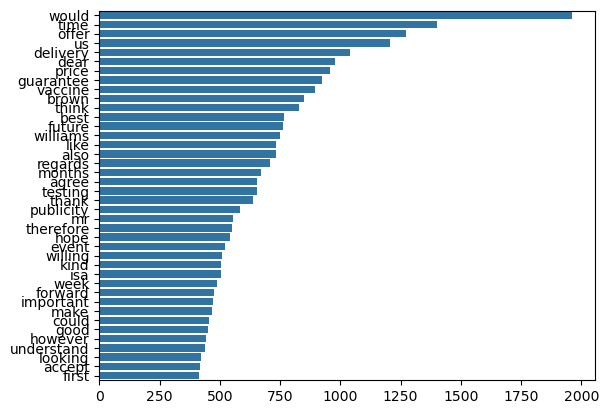

In [45]:
from collections import  Counter

#Top Words, die sich im derzeitigen Corpus befinden nach Häufigkeit sortiert
def plot_topwords_barchart(message):
    new=message.str.split()
    new=new.values.tolist()
    corpus=[word for i in new for word in i]

    counter=Counter(corpus)
    most=counter.most_common()
    x, y=[], []
    
    for word, count in most[:40]:
            x.append(word)
            y.append(count)
            
    sns.barplot(x=y,y=x)

plot_topwords_barchart(df['Content'])

### 3.2.1) BoW

In [49]:
# sklearn 
from sklearn.feature_extraction.text import CountVectorizer

In [50]:
#BoW
'''
Countvectorizer converts a collection of text documents to a matrix of token counts.
'''
#man kann über den CountVecotizer auch bspw. stop-Words entfernen, haben wir aber schon daher lassen wir das nachfolgende Objekt leer
count_vectorizer = CountVectorizer()
message_vectors = count_vectorizer.fit_transform(df['Content'])
message_vectors 

<1150x5996 sparse matrix of type '<class 'numpy.int64'>'
	with 79004 stored elements in Compressed Sparse Row format>

In [51]:
#Nachfolgende Schritte um den Count Vectorizer ausgeben zu können
message_array = message_vectors.toarray()
df_countvectorizer = pd.DataFrame(data=message_array,columns = count_vectorizer.get_feature_names_out())
print(df_countvectorizer)

      abandon  abe  abilities  ability  abilty  able  abovementioned  abroad  \
0           0    0          0        0       0     1               0       0   
1           0    0          0        0       0     1               0       0   
2           0    0          0        0       0     2               0       0   
3           0    0          0        0       0     0               0       0   
4           0    0          0        0       0     1               0       0   
...       ...  ...        ...      ...     ...   ...             ...     ...   
1145        0    0          0        0       0     0               0       0   
1146        0    0          0        0       0     0               0       0   
1147        0    0          0        0       0     0               0       0   
1148        0    0          0        0       0     0               0       0   
1149        0    0          0        0       0     0               0       0   

      absence  absences  ...  youwillia

In [52]:
#So kann man sich ausgeben lassen welche Worte das sind (vereinheitlicht)
df_countvectorizer.columns

Index(['abandon', 'abe', 'abilities', 'ability', 'abilty', 'able',
       'abovementioned', 'abroad', 'absence', 'absences',
       ...
       'youwilliams', 'youwith', 'yy', 'zealand', 'zoom', 'zurich', 'zurick',
       'zürich', 'às', 'ánd'],
      dtype='object', length=5996)

In [53]:
#BoW-Alternative with n-grams
'''
#Set the parameter ngram_range=(a,b) where a is the minimum and b is the maximum size of ngrams
#min_df = 0.01 means "ignore terms that appear in less than 1% of the documents".
# max_df = 0.50 means "ignore terms that appear in more than 50% of the documents".
# max_features: This parameter is pretty self-explanatory. The CountVectorizer will choose the words/features that occur most frequently to be in its’ 
#vocabulary and drop everything else.
'''

#Hier auf max. 100 Dimensionen eingeschränkt unter Berücksichtigung der anderen Kennzahlen
count_vectorizer_ngram = CountVectorizer(ngram_range=(1,2), min_df=0.1, max_df=0.7, max_features=100)
message_vectors_ngram = count_vectorizer_ngram.fit_transform(df['Content'])

In [54]:
message_vectors_ngram.shape

(1150, 100)

In [55]:
#Nachfolgende Schritte um den n-gram based Count Vectorizer ausgeben zu können
message_ngram_array = message_vectors_ngram.toarray()
df_countvectorizer_ngram = pd.DataFrame(data=message_ngram_array, columns = count_vectorizer_ngram.get_feature_names_out())
print(df_countvectorizer_ngram)

      able  accept  agree  agreement  alex  already  also  band  best  \
0        1       0      1          2     0        0     0     0     1   
1        1       1      0          0     0        0     1     0     2   
2        2       5      0          0     0        0     0     0     1   
3        0       1      0          2     0        1     2     0     1   
4        1       0      0          1     0        0     0     0     1   
...    ...     ...    ...        ...   ...      ...   ...   ...   ...   
1145     0       0      0          0     0        0     3     3     2   
1146     0       1      1          1     1        1     0     3     0   
1147     0       0      0          0     0        1     0     2     1   
1148     0       3      0          0     1        1     0     1     1   
1149     0       1      0          0     0        0     0     0     1   

      best regards  ...  want  way  week  well  wide  williams  willing  work  \
0                1  ...     0    0     0  

In [56]:
#alle 100 n-grams (man kann natürlich auch mehr bilden und weitere selektionsansätze durchführen)
df_countvectorizer_ngram.columns

Index(['able', 'accept', 'agree', 'agreement', 'alex', 'already', 'also',
       'band', 'best', 'best regards', 'brown', 'chris', 'come', 'company',
       'conference', 'could', 'course', 'deal', 'dear mr', 'delivery',
       'delivery time', 'event', 'find', 'first', 'forward', 'full',
       'full guarantee', 'future', 'future testing', 'get', 'give', 'good',
       'great', 'guarantee', 'happy', 'hear', 'hope', 'however', 'important',
       'innovax', 'international', 'isa', 'issue', 'issues', 'kind',
       'kind regards', 'know', 'last', 'like', 'looking', 'looking forward',
       'make', 'months', 'mr', 'mr brown', 'mr williams', 'much', 'music',
       'narrow', 'nca', 'need', 'negotiation', 'new', 'offer', 'one', 'per',
       'please', 'point', 'possible', 'price', 'publicity', 'really',
       'regarding', 'regards', 'see', 'since', 'soon', 'sponsor', 'still',
       'take', 'testing', 'thank', 'therefore', 'think', 'time', 'time months',
       'understand', 'us', 'vacci

### 3.2.2) TF-IDF

In [58]:
from sklearn.feature_extraction.text import TfidfVectorizer

#TF-IDF

tfidf_vectorizer = TfidfVectorizer()
tfidf_vectorizer.fit(df['Content'])
tfidf_message_vector = tfidf_vectorizer.transform(df['Content'])

#Gleiches Spiel mit dem min_df, max_df usw. siehe auch hier bei dem Tokenizer erweiterbar, siehe Dokumentation


In [59]:
#Anzahl der Dimensionen identisch zu BoW hoch. Passt auch, da bei TF-IDF keine Dimensionskürzung vorgenommen wird
#Die Berechnungsgrundlage für die Kennzahlen ist hier einfach eine andere
tfidf_message_vector.shape

(1150, 5996)

In [60]:
message_tfidf_array = tfidf_message_vector.toarray()
df_tfidf = pd.DataFrame(data=message_tfidf_array, columns = tfidf_vectorizer.get_feature_names_out())
print(df_tfidf)

      abandon  abe  abilities  ability  abilty      able  abovementioned  \
0         0.0  0.0        0.0      0.0     0.0  0.065453             0.0   
1         0.0  0.0        0.0      0.0     0.0  0.064970             0.0   
2         0.0  0.0        0.0      0.0     0.0  0.112407             0.0   
3         0.0  0.0        0.0      0.0     0.0  0.000000             0.0   
4         0.0  0.0        0.0      0.0     0.0  0.099584             0.0   
...       ...  ...        ...      ...     ...       ...             ...   
1145      0.0  0.0        0.0      0.0     0.0  0.000000             0.0   
1146      0.0  0.0        0.0      0.0     0.0  0.000000             0.0   
1147      0.0  0.0        0.0      0.0     0.0  0.000000             0.0   
1148      0.0  0.0        0.0      0.0     0.0  0.000000             0.0   
1149      0.0  0.0        0.0      0.0     0.0  0.000000             0.0   

      abroad  absence  absences  ...  youwilliams   youwith   yy  zealand  \
0        0